# Part 1 – Data Wrangling and Analysis (Questions 1–3)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("pandas     ", pd.__version__)
print("numpy      ", np.__version__)
print("matplotlib ", matplotlib.__version__)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

pandas      3.0.5
numpy       2.5.3
matplotlib  3.11.2


## Loading the data

In [ ]:
raw = pd.read_csv("artist_streams.csv")
df = raw.copy()         

print("Shape:", df.shape)
print()
print(df.dtypes)
print()
print(df.head().to_string())

Shape: (511, 15)

Artist ID                  int64
Artist Name                  str
Sex                          str
Country of Origin            str
Primary Language             str
Primary Genre                str
Artist Type                  str
Debut Year               float64
Total Streams            float64
Lead Streams             float64
Feature Streams          float64
Solo Streams             float64
Collaborative Streams    float64
Update Date                  str
Year                     float64
dtype: object

   Artist ID    Artist Name     Sex Country of Origin Primary Language Primary Genre Artist Type  Debut Year  Total Streams  Lead Streams  Feature Streams  Solo Streams  Collaborative Streams          Update Date    Year
0          0          Drake    Male            Canada          English       Hip-Hop        Solo      2006.0       137492.1       94851.1          42640.9       53323.9                84168.2  2026-07-01 00:00:00  2026.0
1          1   Taylor Swift  F

## Q1 – Duplicates, missing values and other data quality issues

### 1.1 Duplicates

In [3]:
# Exact duplicate rows (every column identical)
dup_mask = df.duplicated(keep=False)
print("Exact duplicate rows (extra copies):", df.duplicated().sum())
print(df.loc[dup_mask, ["Artist ID", "Artist Name"]].drop_duplicates().to_string(index=False))

# Are there artists repeated with *different* values? (same ID or same name, not exact copies)
no_exact = df.drop_duplicates()
print()
print("Repeated Artist IDs after removing exact copies:  ", no_exact["Artist ID"].dropna().duplicated().sum())
print("Repeated Artist names after removing exact copies:", no_exact["Artist Name"].dropna().str.strip().str.lower().duplicated().sum())

Exact duplicate rows (extra copies): 10
 Artist ID        Artist Name
        45        Linkin Park
       140      Fleetwood Mac
       218         John Mayer
       221   System Of A Down
       263               Zedd
       272          DJ Khaled
       275 Christina Aguilera
       296                 U2
       307          Burna Boy
       441         Disclosure

Repeated Artist IDs after removing exact copies:   0
Repeated Artist names after removing exact copies: 0


There are **10 exact duplicate rows** (Linkin Park, Fleetwood Mac, John Mayer, System Of A Down, Zedd, DJ Khaled, Christina Aguilera, U2, Burna Boy, Disclosure).
Every column is identical, so they are copies of the same record: keeping them would count these artists twice. We keep the first copy and drop the rest.
After that, no ID or name is repeated.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (501, 15)


### 1.2 Missing values

In [5]:
missing = df.isna().sum()
print(missing[missing > 0].to_string())

Artist Name               1
Sex                      23
Country of Origin         1
Primary Language          1
Primary Genre             1
Artist Type               1
Debut Year                1
Total Streams             6
Lead Streams              7
Feature Streams          10
Solo Streams              5
Collaborative Streams     2
Update Date               1
Year                      1


In [6]:
# One row has almost every column empty: it carries no information about any artist
empty_rows = df[df.drop(columns="Artist ID").isna().all(axis=1)]
print(empty_rows.to_string())

     Artist ID Artist Name  Sex Country of Origin Primary Language Primary Genre Artist Type  Debut Year  Total Streams  Lead Streams  Feature Streams  Solo Streams  Collaborative Streams Update Date  Year
500        500         NaN  NaN               NaN              NaN           NaN         NaN         NaN            NaN           NaN              NaN           NaN                    NaN         NaN   NaN


Artist ID 500 is an **empty row**: everything except the ID is missing, so there is nothing to recover. We drop it.

In [7]:
df = df.drop(index=empty_rows.index).reset_index(drop=True)
missing = df.isna().sum()
print("Shape:", df.shape)
print(missing[missing > 0].to_string())

Shape: (500, 15)
Sex                      22
Total Streams             5
Lead Streams              6
Feature Streams           9
Solo Streams              4
Collaborative Streams     1


#### Missing `Sex`

In [8]:
print(pd.crosstab(df["Artist Type"], df["Sex"].fillna("MISSING")))

Sex          Female  MISSING  Male
Artist Type                       
Group             6       22    99
Solo             82        0   291


All 22 missing values of `Sex` belong to **groups**. Solo artists are never missing it.
A group can be mixed, so a single sex often does not apply. We don't want to guess or drop these artists, so we fill the gap with the category **"Unknown"**.

In [9]:
df["Sex"] = df["Sex"].fillna("Unknown")
print(df["Sex"].value_counts().to_string())

Sex
Male       390
Female      88
Unknown     22


#### Missing stream values

The brief says the streams can be split two ways:

* Total = Solo + Collaborative
* Total = Lead + Feature

Before using these to fill the gaps, we check how well each one holds on the complete rows.

In [10]:
s = ["Total Streams", "Lead Streams", "Feature Streams", "Solo Streams", "Collaborative Streams"]

diff_solo_collab = df["Total Streams"] - df["Solo Streams"] - df["Collaborative Streams"]
diff_lead_feat   = df["Total Streams"] - df["Lead Streams"] - df["Feature Streams"]

print("Total - (Solo + Collab), in millions:")
print(diff_solo_collab.round(1).describe().to_string())
print()
print("Total - (Lead + Feature), in millions:")
print(diff_lead_feat.round(1).describe().to_string())
print()
print("Rows where Lead > Total:", (df["Lead Streams"] > df["Total Streams"]).sum())

Total - (Solo + Collab), in millions:
count    490.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0

Total - (Lead + Feature), in millions:
count    480.000000
mean      -5.367292
std        9.369434
min      -39.200000
25%       -9.150000
50%       -5.000000
75%       -1.275000
max       89.200000

Rows where Lead > Total: 38


* **Total = Solo + Collaborative holds exactly** for every complete row, so we can use it to fill gaps with no error.
* **Total = Lead + Feature only holds approximately.** Lead + Feature is usually a few million streams (at most ~90M) away from Total, which is under 1% for these artists. 38 artists even have Lead > Total.
  This is a data quality issue in itself. It is small and affects almost every row, so we keep the original values rather than "correcting" them.

**Filling strategy:** we compute each missing value from the other columns. Solo/Collab are filled from the exact identity. Lead/Feature are filled from the approximate one, and negative results (when Lead > Total) are set to 0.
This keeps all 500 artists. Dropping the 25 rows with gaps, which include big names like Future and Harry Styles, would bias the analysis.

In [11]:
before = df[s].isna().any(axis=1)
rows_with_gaps = df.index[before]

# Total: use the exact identity first, fall back on Lead + Feature
df["Total Streams"] = (df["Total Streams"]
                       .fillna(df["Solo Streams"] + df["Collaborative Streams"])
                       .fillna(df["Lead Streams"] + df["Feature Streams"]))

# Solo / Collaborative: exact
df["Solo Streams"]          = df["Solo Streams"].fillna(df["Total Streams"] - df["Collaborative Streams"])
df["Collaborative Streams"] = df["Collaborative Streams"].fillna(df["Total Streams"] - df["Solo Streams"])

# Lead / Feature: approximate, can't be negative
df["Lead Streams"]    = df["Lead Streams"].fillna((df["Total Streams"] - df["Feature Streams"]).clip(lower=0))
df["Feature Streams"] = df["Feature Streams"].fillna((df["Total Streams"] - df["Lead Streams"]).clip(lower=0))

df[s] = df[s].round(1)

print("Missing stream values left:", df[s].isna().sum().sum())
print()
print(df.loc[rows_with_gaps, ["Artist Name"] + s].to_string(index=False))

Missing stream values left: 0

        Artist Name  Total Streams  Lead Streams  Feature Streams  Solo Streams  Collaborative Streams
             Future        53951.5       27879.0          26072.5       12647.5                41304.0
         Peso Pluma        33179.8       18699.1          14501.2        3938.3                29241.5
       Harry Styles        29449.0       29462.8              0.0       29449.0                    0.0
               Kygo        19707.8       17824.5           1883.3         250.7                19457.1
          Sean Paul        18203.3        9663.9           8539.4        4460.6                13742.7
         Bebe Rexha        17440.2        5928.1          11512.1        2784.0                14656.2
      Fleetwood Mac        16577.5       16577.5              0.0       16567.4                   10.1
        A.R. Rahman        15240.4       10857.5           4397.5         594.9                14645.5
            ROSALÍA        14558.4       1

### 1.3 Other data quality issues

In [12]:
# Data types: years are stored as floats and the update date as text
print(df[["Debut Year", "Year", "Update Date"]].dtypes.to_string())
print()
# Categories that look inconsistent
print("Genres with the typo:", df.loc[df["Primary Genre"] == "Sertanjeo", "Artist Name"].tolist())
print("'Nu Metal' artists:   ", df.loc[df["Primary Genre"] == "Nu Metal", "Artist Name"].tolist())
print("Other nu-metal bands: ", df.loc[df["Artist Name"].isin(["Korn", "Slipknot", "Deftones"]), ["Artist Name", "Primary Genre"]].values.tolist())
print("'Scotland' artists:   ", df.loc[df["Country of Origin"] == "Scotland", "Artist Name"].tolist())

Debut Year     float64
Year           float64
Update Date        str

Genres with the typo: ['Henrique & Juliano', 'Marília Mendonça', 'Jorge & Mateus', 'Gusttavo Lima', 'Zé Neto & Cristiano', 'Matheus & Kauan', 'Ana Castela', 'Luan Santana', 'Maiara & Maraisa']
'Nu Metal' artists:    ['Limp Bizkit']
Other nu-metal bands:  [['Slipknot', 'Metal'], ['Deftones', 'Metal'], ['Korn', 'Metal']]
'Scotland' artists:    ['Calvin Harris', 'Lewis Capaldi']


Fixes:

1. **Data types**: `Debut Year` and `Year` become integers and `Update Date` becomes a datetime, so we can do date arithmetic in Q3.
2. **Typo**: "Sertanjeo" becomes **"Sertanejo"**, the correct name of the Brazilian genre.
3. **Inconsistent genre label**: Limp Bizkit is the only artist labelled "Nu Metal", while similar bands (Korn, Slipknot, Deftones) are "Metal". We merge it into **"Metal"** so the genre comparison isn't split by a one-artist category.
4. **Inconsistent country level**: Calvin Harris and Lewis Capaldi are listed under "Scotland", while every other British artist is under "United Kingdom". Scotland is part of the UK, so we map it to **"United Kingdom"** to keep one level of detail (country).

In [13]:
df["Debut Year"]  = df["Debut Year"].astype(int)
df["Year"]        = df["Year"].astype(int)
df["Update Date"] = pd.to_datetime(df["Update Date"])

df["Primary Genre"]     = df["Primary Genre"].replace({"Sertanjeo": "Sertanejo", "Nu Metal": "Metal"})
df["Country of Origin"] = df["Country of Origin"].replace({"Scotland": "United Kingdom"})

print(df[["Debut Year", "Year", "Update Date"]].dtypes.to_string())

Debut Year              int64
Year                    int64
Update Date    datetime64[us]


**Issues we noted but kept as they are** (changing them would mean inventing information):

* **Lead + Feature ≠ Total** by a small amount for most artists (see above).
* **Puerto Rican artists** (e.g. Bad Bunny, Chencho Corleone) are listed under "United States". Puerto Rico is a US territory, so this is defensible, but it slightly inflates the US count.
* **Non-artist entries**: "Disney" and "League of Legends" are franchises, not musicians.
* **Overlapping entries**: "Macklemore & Ryan Lewis" appears alongside "Macklemore" and "Ryan Lewis", so some streams may be counted more than once.

In [14]:
# Final check of the cleaned data, then save it for the rest of the group
print("Final shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicated IDs:", df["Artist ID"].duplicated().sum())

df.to_csv("artist_streams_clean.csv", index=False)

Final shape: (500, 15)
Missing values: 0
Duplicated IDs: 0


## Q2 – Describing the artists

### Q2 a) Unique artists and pop artists

In [15]:
n_artists = df["Artist ID"].nunique()
n_pop     = (df["Primary Genre"] == "Pop").sum()
n_kpop    = (df["Primary Genre"] == "K-Pop").sum()

print("Unique artists:", n_artists)
print("Pop artists:   ", n_pop)
print("(K-Pop artists, counted as a separate genre:", n_kpop, ")")

Unique artists: 500
Pop artists:    102
(K-Pop artists, counted as a separate genre: 11 )


There are **500 unique artists**. **102** have Pop as their primary genre.
K-Pop is a separate genre in the data (11 artists), so we don't include it in the Pop count.

### Q2 b) Most common primary genre

In [16]:
genre_counts = df["Primary Genre"].value_counts()
print(genre_counts.head(5).to_string())

Primary Genre
Hip-Hop      115
Pop          102
Rock          60
Reggaeton     43
R&B           31


The most common primary genre is **Hip-Hop, with 115 artists**, ahead of Pop (102).

### Q2 c) Most common country of origin

In [17]:
country_counts = df["Country of Origin"].value_counts()
print(country_counts.head(5).to_string())

Country of Origin
United States     265
United Kingdom     57
Mexico             27
Canada             18
Colombia           16


The most common country of origin is the **United States, with 265 artists**, more than half of the dataset.

### Q2 d) Top 3 primary languages

Primary Language
English       340
Spanish       105
Portuguese     15


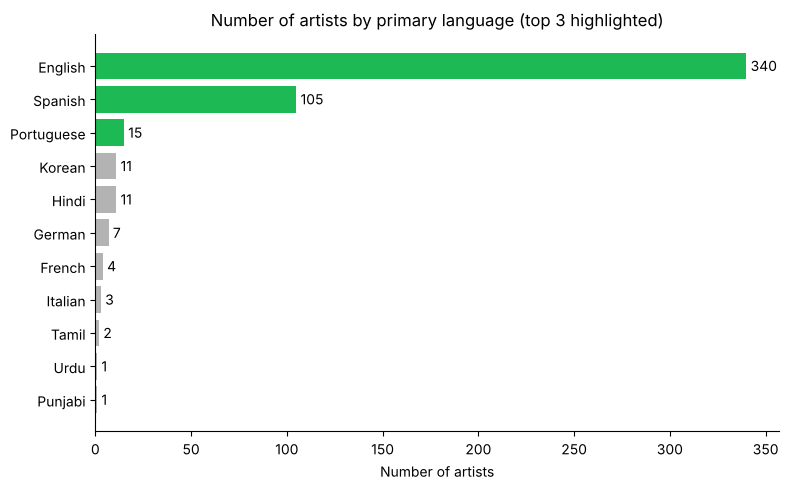

In [18]:
lang_counts = df["Primary Language"].value_counts().sort_values()
colors = ["#1DB954" if lang in lang_counts.tail(3).index else "#B3B3B3" for lang in lang_counts.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(lang_counts.index, lang_counts.values, color=colors)
ax.bar_label(bars, padding=3)
ax.set_title("Number of artists by primary language (top 3 highlighted)")
ax.set_xlabel("Number of artists")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(lang_counts.sort_values(ascending=False).head(3).to_string())

The top 3 primary languages are **English (340 artists)**, **Spanish (105)** and **Portuguese (15)**.
English dominates, with about two thirds of all artists.

## Q3 – Update dates

### Q3 a) Most recent and oldest updates

In [19]:
today  = pd.Timestamp.today().normalize()
newest = df["Update Date"].max()
oldest = df["Update Date"].min()

for label, date in [("Most recent", newest), ("Oldest", oldest)]:
    print(f"{label} update: {date:%d %B %Y} ({date:%A}), {(today - date).days} days ago")
print(f"(computed on {today:%d %B %Y})")

print()
print(df["Update Date"].value_counts().to_string())

Most recent update: 01 July 2026 (Wednesday), 144 days ago
Oldest update: 01 July 2025 (Tuesday), 509 days ago
(computed on 22 November 2026)

Update Date
2026-07-01    490
2025-07-01     10


The **most recent update was on 1 July 2026** and the **oldest on 1 July 2025**, exactly one year earlier.
The "days ago" values depend on the day the notebook is run (the cell above prints the date used). On 22 November 2026, they were 144 and 509 days.

### Q3 b) Artists with out-of-date stream counts

In [20]:
cutoff = pd.Timestamp("2025-12-31")
outdated = df[df["Update Date"] <= cutoff]

print("Artists last updated before the end of 2025:", len(outdated))
print(outdated[["Artist Name", "Update Date", "Total Streams"]]
      .sort_values("Total Streams", ascending=False).to_string(index=False))

Artists last updated before the end of 2025: 10
        Artist Name Update Date  Total Streams
              Quavo  2025-07-01        19383.5
         Gucci Mane  2025-07-01        14880.2
     Grupo Frontera  2025-07-01        13999.3
      Elvis Presley  2025-07-01        11588.8
        Teddy Swims  2025-07-01         9177.5
Alejandro Fernández  2025-07-01         8617.1
          SEVENTEEN  2025-07-01         8531.3
        ScHoolboy Q  2025-07-01         7817.3
         Kane Brown  2025-07-01         7313.2
 Grupo Menos É Mais  2025-07-01         7277.6


Yes. **10 artists** were last updated on 1 July 2025 and need their stream counts updated:
Quavo, Gucci Mane, Grupo Frontera, Elvis Presley, Teddy Swims, Alejandro Fernández, SEVENTEEN, ScHoolboy Q, Kane Brown and Grupo Menos É Mais.
Their totals are a year behind everyone else's, so comparing them directly with other artists slightly underestimates them.